# Astra three-trial persona analysis

Reproducible notebook for the benchmark and super-family tables and annotated bar plots. Covers **Off, 148, 155, 089, 001, 127**, trials 1–3. Uses a frozen normalized snapshot; **no model/API calls**. Run cells in order with a Python kernel containing NumPy and Matplotlib.

The saved outputs are executed from the cells using Python. Plots are also exported as PNG, PDF and editable SVG. This notebook is the plotting entry point for tracking this analysis.

In [1]:
from pathlib import Path
import json, csv, hashlib
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

# Works from the repository root or this notebook's directory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "Experiment/shared/task_selection.csv").exists())
BASE = ROOT / "Experiment/02_performance_and_fields"
OUT = BASE / "data/three_trials"
FIG = BASE / "figures/three_trials"
FIG.mkdir(parents=True, exist_ok=True)
ARMS=['persona_off','candidate_148','candidate_155','candidate_089','candidate_001','candidate_127']
SOURCES=['asibench','bixbench','discoverybench','expbench','sciconvbench']
FAMILIES=['life','physical_engineering','math_cs','social_humanities']
NAMES=dict(zip(SOURCES,['ASI-Bench*','BixBench','DiscoveryBench','EXP-Bench','SciConvBench']))
NAMES.update(dict(zip(FAMILIES,['Life sciences','Physical sciences & engineering','Math & computer science','Social sciences & humanities'])))
LABELS=['Off','148','155','089','001','127']
COLORS=['#65758B','#0072B2','#E69F00','#009E73','#CC79A7','#D55E00']
B=20000;SEED=20260930


## Frozen data and provenance

The snapshot includes original outcomes and the latest outcomes after one repair pass. Repairs replace an episode outcome within its original trial; they are **not additional independent trials**. Hashes record the raw files used to create the snapshot. The notebook can run from tracked snapshot data without access to raw run directories.

In [2]:
snapshot = json.loads((OUT / "snapshot.json").read_text())
episodes = snapshot["episodes"]
selection = list(csv.DictReader((ROOT / "Experiment/shared/task_selection.csv").open()))
assert len(episodes) == 7200
assert len({(r["view"], r["trial"], r["source"], r["task_id"], r["arm"]) for r in episodes}) == 7200
print("Snapshot:", snapshot["captured_at_utc"])
print("Records:", len(episodes), "= 2 outcome views × 6 conditions × 3 trials × 200 tasks")
print("Snapshot SHA256:", hashlib.sha256((OUT / "snapshot.json").read_bytes()).hexdigest())
for record in snapshot["provenance"]:
    print(record["view"], "trial", record["trial"], record["file"], record["sha256"])


Snapshot: 2026-09-30T15:19:45.436866+00:00
Records: 7200 = 2 outcome views × 6 conditions × 3 trials × 200 tasks
Snapshot SHA256: 8b3f00d0933cd01131a18f9a6088d250c288ca6c933f3fce5d42d5132776eb12
original trial 1 runs/repair-1-openai-astra-top10-trial-1-batch-2/original_results_snapshot.json aae45594d7123c9c3a347003a0f772f97c61d6eea78679f04f7d605413d6af3d
after_repair trial 1 runs/repair-1-openai-astra-top10-trial-1-batch-2/results.json 96f8efcbeec748fe59ba2c4b9c7d74855bf819f4d967fbe1ece7dc0ecaf22d6c
original trial 2 runs/repair-1-openai-astra-top10-trial-2-batch-2/original_results_snapshot.json 4c5eb6c5ed5a49c198c0c178e0743b262ac6c23a9f3e4b5a8a49a42e6d9af01a
after_repair trial 2 runs/repair-1-openai-astra-top10-trial-2-batch-2/results.json b14d2ff87200324bc4ff2b7ec787a18c8675686e6bc3ebd7d3b6348c506fe3a1
original trial 3 runs/repair-1-openai-astra-top10-trial-3-batch-2/original_results_snapshot.json 6337308188fb7feb911dd2bc4310d8789e9e5411ddfd0f11bc77cbf00460a5cf
after_repair trial 3 ru

## Aggregation and 95% confidence intervals

1. Missing submissions score zero; technical errors and other unscored episodes are excluded.
2. Average the available one to three trial scores for each task and persona.
3. Give each evaluable task equal weight.
4. Resample study clusters within each benchmark, preserving observed source weights, for **20,000 percentile-bootstrap draws**, seed **20260930**. Tasks from the same study move together.

These pointwise intervals describe study/task sampling uncertainty conditional on observed trial outcomes, not a separate estimate of trial randomness. Unequal coverage, conditional retries and historical ASI evaluator changes limit comparisons. Family scores combine different normalized native metrics; CI overlap is not a significance test.

In [3]:
rng=np.random.default_rng(SEED)
summaries={};coverage={}
for view in ['original','after_repair']:
 summaries[view]={};coverage[view]={}
 for arm in ARMS:
  rows=[r for r in episodes if r['view']==view and r['arm']==arm]
  coverage[view][arm]=dict(Counter(r['status'] for r in rows))
  tasks=[]
  for meta in selection:
   rr=[r for r in rows if (r['source'],r['task_id'])==(meta['source'],meta['task_id']) and r['score'] is not None]
   if rr:tasks.append({**rr[0],'score':float(np.mean([r['score'] for r in rr])),'trials_available':len(rr)})
  summaries[view][arm]={}
  for field,groups in [('source',SOURCES),('family',FAMILIES)]:
   summaries[view][arm][field]={}
   for group in groups:
    sub=[t for t in tasks if t[field]==group];assert sub
    boot=np.zeros(B)
    cluster_counts={}
    # Resample studies within each source; preserve observed source weights.
    # All tasks in a sampled study move together; trial means are computed first.
    for source in SOURCES:
     ss=[t for t in sub if t['source']==source]
     if not ss:continue
     clusters=sorted({t['study_id'] for t in ss});cluster_counts[source]=len(clusters)
     sums=np.array([sum(t['score'] for t in ss if t['study_id']==c) for c in clusters])
     counts=np.array([sum(t['study_id']==c for t in ss) for c in clusters])
     weights=rng.multinomial(len(clusters),np.ones(len(clusters))/len(clusters),size=B)
     boot+=(weights@sums)/(weights@counts)*len(ss)/len(sub)
    summaries[view][arm][field][group]={'mean':float(np.mean([t['score'] for t in sub])),'ci95':np.quantile(boot,[.025,.975]).tolist(),'tasks':len(sub),'episodes':sum(t['trials_available'] for t in sub),'tasks_all_three_trials':sum(t['trials_available']==3 for t in sub),'source_counts':dict(Counter(t['source'] for t in sub)),'study_clusters_by_source':cluster_counts}


## Coverage and validation

`n` is the number of distinct evaluable tasks; `e` is the number of evaluable trial episodes. Complete-three-trial coverage is recorded separately in the summary.

In [4]:
for arm in ARMS:
    c = coverage["after_repair"][arm]
    assert sum(c.values()) == 600
    print(arm, c)
for view, arms in summaries.items():
    for arm, fields in arms.items():
        observed = sum(r["score"] is not None for r in episodes if r["view"] == view and r["arm"] == arm)
        for groups in fields.values():
            assert sum(s["episodes"] for s in groups.values()) == observed
            for s in groups.values():
                assert 0 <= s["ci95"][0] <= s["mean"] <= s["ci95"][1] <= 100
                assert s["tasks"] <= s["episodes"] <= 3*s["tasks"]
# Same snapshot, method and seed must reproduce the standalone report exactly.
saved = json.loads((OUT / "summary.json").read_text())
assert summaries == saved["summaries"]
print("All 108 cells match the saved report; coverage and CI checks passed.")


persona_off {'scored': 549, 'infrastructure_error': 40, 'missing_submission': 11}
candidate_148 {'scored': 553, 'missing_submission': 12, 'infrastructure_error': 35}
candidate_155 {'scored': 526, 'infrastructure_error': 62, 'missing_submission': 12}
candidate_089 {'scored': 577, 'missing_submission': 18, 'infrastructure_error': 5}
candidate_001 {'scored': 578, 'missing_submission': 16, 'infrastructure_error': 6}
candidate_127 {'scored': 576, 'missing_submission': 15, 'infrastructure_error': 9}
All 108 cells match the saved report; coverage and CI checks passed.


In [5]:
def table(view,field,groups):
 lines=['| Persona | '+' | '.join(NAMES[g] for g in groups)+' |','|---|'+'---|'*len(groups)]
 for arm,label in zip(ARMS,LABELS):
  cells=[]
  for g in groups:
   s=summaries[view][arm][field][g];lo,hi=s['ci95']
   cells.append(f"{s['mean']:.2f} [{lo:.2f}, {hi:.2f}]; n={s['tasks']}, e={s['episodes']}")
  lines.append('| '+label+' | '+' | '.join(cells)+' |')
 return '\n'.join(lines)


## Table 1 — Benchmark performance

Mean [95% CI]; n=tasks, e=trial episodes. ASI results retain historical evaluator differences.

In [6]:
print(table("after_repair", "source", SOURCES))


| Persona | ASI-Bench* | BixBench | DiscoveryBench | EXP-Bench | SciConvBench |
|---|---|---|---|---|---|
| Off | 48.16 [37.76, 58.87]; n=39, e=99 | 32.46 [8.89, 56.10]; n=38, e=104 | 13.14 [6.06, 16.73]; n=40, e=117 | 43.95 [36.55, 51.20]; n=40, e=120 | 85.00 [75.00, 94.17]; n=40, e=120 |
| 148 | 49.56 [38.74, 60.29]; n=40, e=100 | 30.00 [7.32, 54.00]; n=40, e=111 | 13.66 [9.31, 15.66]; n=40, e=114 | 44.04 [36.94, 51.05]; n=40, e=120 | 85.83 [75.83, 94.17]; n=40, e=120 |
| 155 | 53.67 [42.51, 64.59]; n=39, e=98 | 30.83 [8.33, 54.55]; n=40, e=103 | 15.27 [7.74, 21.77]; n=40, e=110 | 43.05 [35.78, 50.35]; n=40, e=107 | 85.00 [75.83, 93.33]; n=40, e=120 |
| 089 | 50.16 [39.86, 60.46]; n=40, e=118 | 30.83 [8.11, 54.55]; n=40, e=118 | 14.79 [7.96, 20.39]; n=40, e=119 | 45.68 [37.34, 53.99]; n=40, e=120 | 87.50 [78.33, 95.83]; n=40, e=120 |
| 001 | 51.85 [41.21, 62.74]; n=40, e=117 | 30.83 [7.89, 54.17]; n=40, e=119 | 14.50 [7.09, 22.80]; n=40, e=118 | 44.61 [37.16, 52.27]; n=40, e=120 | 90

## Table 2 — Super-family performance

Task-weighted composite of normalized native scores, with observed source composition preserved.

In [7]:
print(table("after_repair", "family", FAMILIES))


| Persona | Life sciences | Physical sciences & engineering | Math & computer science | Social sciences & humanities |
|---|---|---|---|---|
| Off | 28.76 [10.06, 47.38]; n=48, e=131 | 66.91 [58.86, 74.38]; n=62, e=174 | 50.67 [43.67, 57.20]; n=55, e=161 | 14.97 [8.33, 18.33]; n=32, e=94 |
| 148 | 26.69 [8.38, 46.01]; n=50, e=137 | 67.26 [59.37, 74.45]; n=63, e=176 | 52.36 [45.24, 59.05]; n=55, e=158 | 14.75 [12.16, 15.81]; n=32, e=94 |
| 155 | 28.12 [10.00, 47.10]; n=50, e=126 | 67.25 [59.63, 74.57]; n=62, e=175 | 52.99 [46.03, 59.39]; n=55, e=147 | 17.80 [12.10, 24.89]; n=32, e=90 |
| 089 | 27.68 [9.52, 46.80]; n=50, e=147 | 68.35 [60.81, 75.35]; n=63, e=189 | 53.41 [46.09, 60.51]; n=55, e=164 | 16.59 [10.81, 22.80]; n=32, e=95 |
| 001 | 27.24 [9.26, 46.49]; n=50, e=146 | 69.71 [62.27, 76.53]; n=63, e=188 | 54.15 [47.34, 60.60]; n=55, e=164 | 16.86 [9.98, 26.52]; n=32, e=96 |
| 127 | 27.70 [9.75, 46.71]; n=50, e=147 | 68.53 [60.96, 75.48]; n=63, e=186 | 54.54 [47.38, 61.32]; n=55, e=

## Annotated bar figures

Edit colors, labels, layout or axis formatting here. Each figure prints the mean and confidence bounds above each bar and task/episode coverage below. This cell exports `benchmark` and `superfamily` in PNG, PDF and SVG, then displays the figures inline.

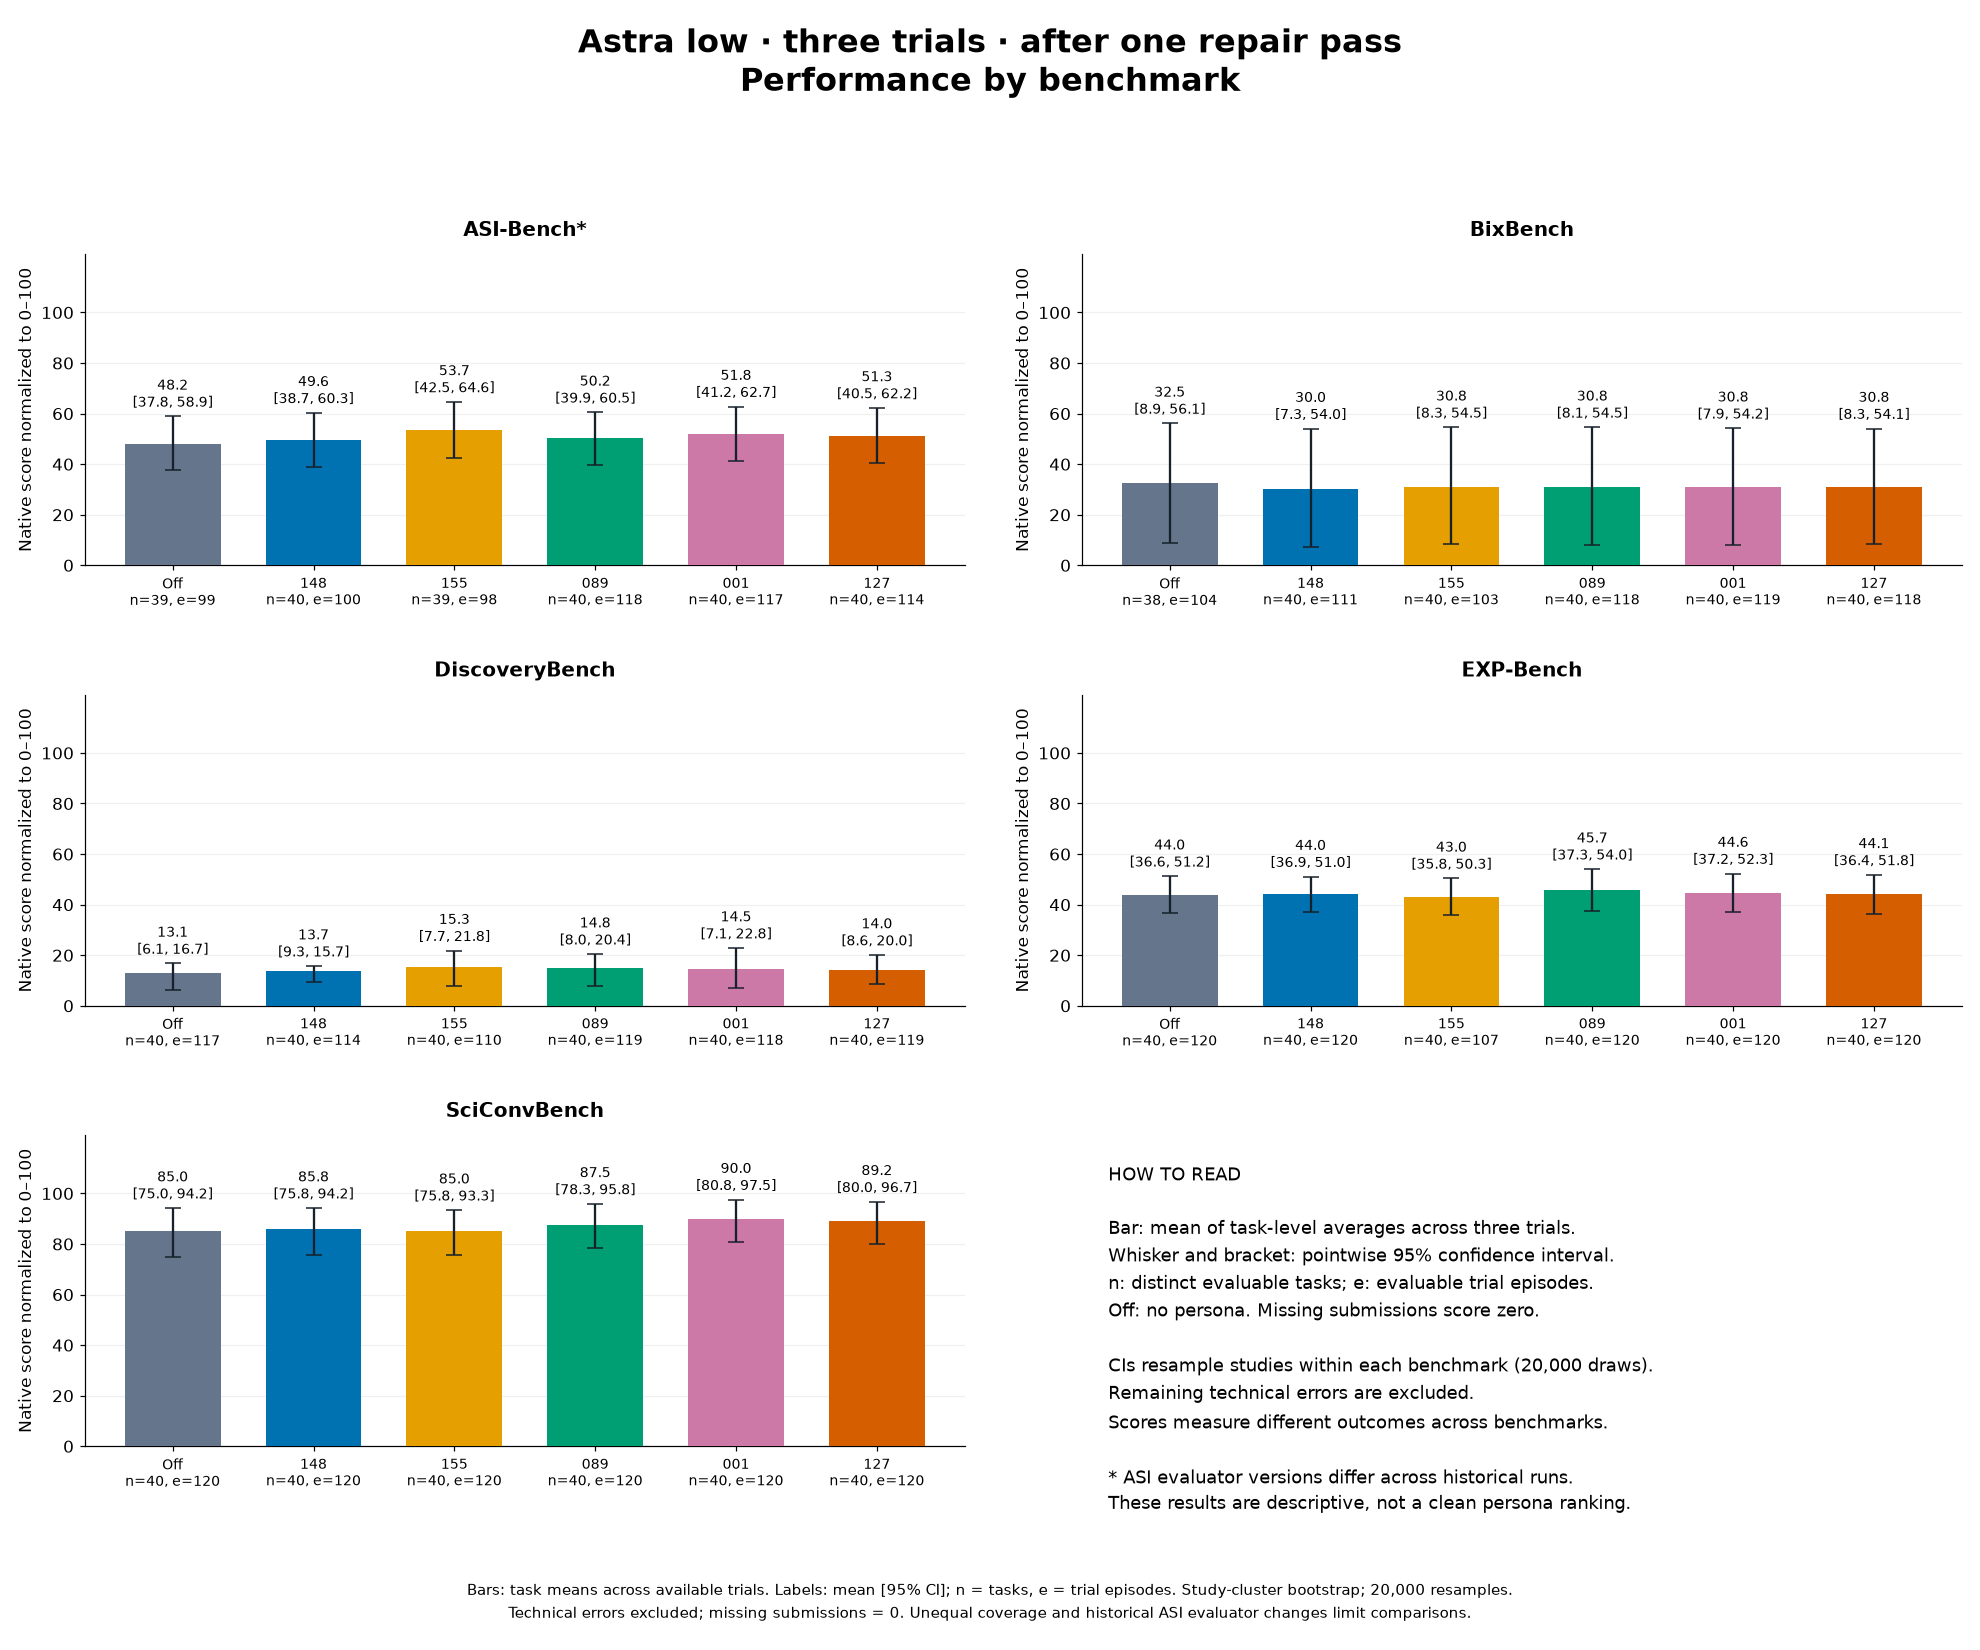

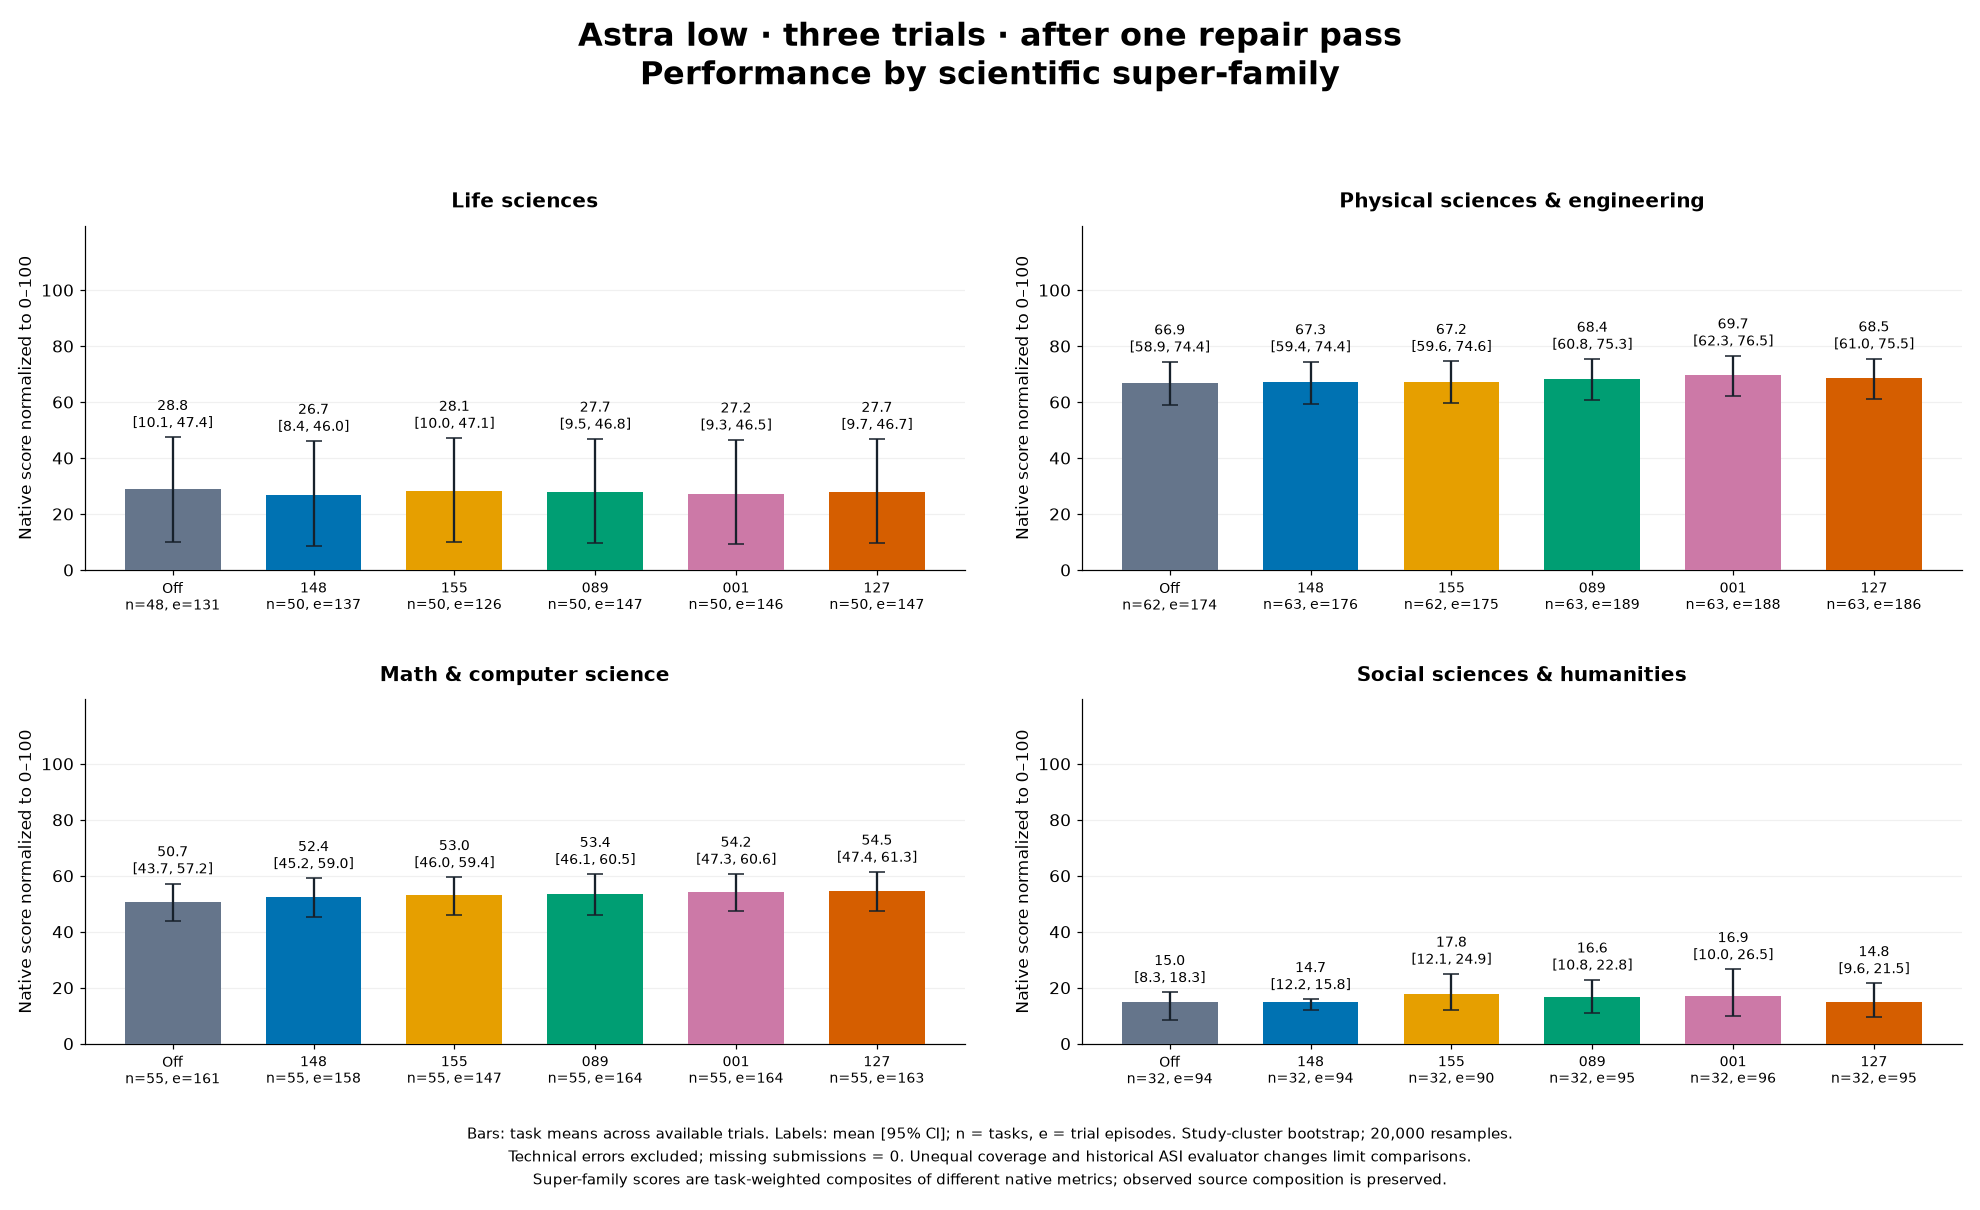

In [8]:
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False,'pdf.fonttype':42,'svg.fonttype':'none'})
for field,groups,title,filename in [('source',SOURCES,'Performance by benchmark','benchmark'),('family',FAMILIES,'Performance by scientific super-family','superfamily')]:
 fig,axes=plt.subplots(3 if field=='source' else 2,2,figsize=(18,15 if field=='source' else 11),squeeze=False)
 for ax,g in zip(axes.flat,groups):
  stats=[summaries['after_repair'][arm][field][g] for arm in ARMS]
  means=np.array([s['mean'] for s in stats]);low=np.array([s['ci95'][0] for s in stats]);high=np.array([s['ci95'][1] for s in stats]);x=np.arange(6)
  ax.bar(x,means,color=COLORS,width=.68,zorder=3)
  ax.errorbar(x,means,yerr=np.array([means-low,high-means]).clip(0),fmt='none',ecolor='#17212B',capsize=5,lw=1.5,zorder=4)
  for i,s in enumerate(stats):
   ax.text(i,max(high[i],means[i])+2,f"{means[i]:.1f}\n[{low[i]:.1f}, {high[i]:.1f}]",ha='center',va='bottom',fontsize=9)
  ax.set_xticks(x,[f'{label}\nn={s["tasks"]}, e={s["episodes"]}' for label,s in zip(LABELS,stats)],fontsize=9)
  ax.set_ylim(0,123);ax.set_yticks([0,20,40,60,80,100]);ax.set_title(NAMES[g],fontweight='bold',pad=12)
  ax.set_ylabel('Native score normalized to 0–100');ax.grid(axis='y',alpha=.18,zorder=0);ax.set_axisbelow(True)
 if field=='source':
  axes.flat[-1].axis('off');axes.flat[-1].text(.03,.92,'HOW TO READ\n\nBar: mean of task-level averages across three trials.\nWhisker and bracket: pointwise 95% confidence interval.\nn: distinct evaluable tasks; e: evaluable trial episodes.\nOff: no persona. Missing submissions score zero.\n\nCIs resample studies within each benchmark (20,000 draws).\nRemaining technical errors are excluded.\nScores measure different outcomes across benchmarks.\n\n* ASI evaluator versions differ across historical runs.\nThese results are descriptive, not a clean persona ranking.',transform=axes.flat[-1].transAxes,va='top',fontsize=12,linespacing=1.5)
 fig.suptitle('Astra low · three trials · after one repair pass\n'+title,fontsize=21,fontweight='bold',y=.985)
 footer='Bars: task means across available trials. Labels: mean [95% CI]; n = tasks, e = trial episodes. Study-cluster bootstrap; 20,000 resamples.\nTechnical errors excluded; missing submissions = 0. Unequal coverage and historical ASI evaluator changes limit comparisons.'
 if field=='family':footer+='\nSuper-family scores are task-weighted composites of different native metrics; observed source composition is preserved.'
 fig.text(.5,.015,footer,ha='center',va='bottom',fontsize=10,linespacing=1.5)
 fig.tight_layout(rect=[0,.085,1,.935],h_pad=3,w_pad=3)
 for ext in ['png','pdf','svg']:fig.savefig(FIG/f'{filename}.{ext}',dpi=180,facecolor='white')
 plt.show()
 plt.close(fig)


## Original-outcome sensitivity tables

Original results are kept separate to expose the effect of the conditional repair pass.

In [9]:
print(table("original", "source", SOURCES))
print()
print(table("original", "family", FAMILIES))


| Persona | ASI-Bench* | BixBench | DiscoveryBench | EXP-Bench | SciConvBench |
|---|---|---|---|---|---|
| Off | 47.55 [37.10, 58.33]; n=38, e=93 | 30.83 [8.33, 54.39]; n=40, e=117 | 13.33 [6.06, 17.18]; n=40, e=115 | 43.95 [36.46, 51.19]; n=40, e=120 | 85.00 [74.98, 94.17]; n=40, e=120 |
| 148 | 49.92 [38.70, 61.09]; n=38, e=91 | 30.00 [7.32, 54.00]; n=40, e=117 | 13.74 [9.66, 15.66]; n=40, e=111 | 44.04 [37.07, 51.11]; n=40, e=120 | 85.83 [75.83, 94.17]; n=40, e=120 |
| 155 | 52.69 [41.67, 63.68]; n=39, e=96 | 30.83 [8.33, 54.49]; n=40, e=117 | 15.38 [7.74, 21.74]; n=40, e=107 | 43.15 [35.75, 50.37]; n=40, e=105 | 85.00 [75.83, 92.50]; n=40, e=120 |
| 089 | 50.39 [40.13, 60.90]; n=40, e=109 | 31.25 [8.57, 54.55]; n=40, e=117 | 14.72 [8.18, 20.19]; n=40, e=108 | 45.68 [37.48, 53.99]; n=40, e=119 | 87.50 [78.33, 95.83]; n=40, e=119 |
| 001 | 51.61 [40.86, 62.29]; n=40, e=109 | 30.83 [8.55, 54.67]; n=40, e=119 | 14.72 [7.27, 22.80]; n=40, e=115 | 44.45 [37.06, 52.13]; n=40, e=105 | 90.

## Artifacts

- [Full report and figure captions](three_trial_persona_results.md)
- [Benchmark PDF](figures/three_trials/benchmark.pdf) · [SVG](figures/three_trials/benchmark.svg)
- [Super-family PDF](figures/three_trials/superfamily.pdf) · [SVG](figures/three_trials/superfamily.svg)
- [Summary and denominators](data/three_trials/summary.json)
- [Episode CSV](data/three_trials/episodes.csv)

To refresh the frozen snapshot from raw runs, run `code/report_three_trials.py` deliberately, then rerun this notebook. Ordinary notebook execution uses the existing snapshot.